Q1. Create NumPy arrays using intrinsic objects and random functions. Perform reshaping and joining.

In [10]:
import numpy as np

a = np.arange(1, 7)
b = np.zeros(3)
c = np.ones(3)
d = np.linspace(0, 1, 5)
e = np.eye(3)
r1 = np.random.randint(1, 100, 6)
r2 = np.random.rand(3)

m = a.reshape(2, 3)
n = r1.reshape(2, 3)

print(a, b, c, d, e, r1, r2, sep='\n')
print(m)
print(np.concatenate([a, r1]))
print(np.vstack((m, n)))
print(np.hstack((m, n)))

[1 2 3 4 5 6]
[0. 0. 0.]
[1. 1. 1.]
[0.   0.25 0.5  0.75 1.  ]
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
[51 43 92  1 72 97]
[0.17964382 0.85784735 0.00695072]
[[1 2 3]
 [4 5 6]]
[ 1  2  3  4  5  6 51 43 92  1 72 97]
[[ 1  2  3]
 [ 4  5  6]
 [51 43 92]
 [ 1 72 97]]
[[ 1  2  3 51 43 92]
 [ 4  5  6  1 72 97]]


Q2. Import a CSV file into a Pandas DataFrame. Detect missing values, handle them by filling or dropping, detect possible outliers, and display statistical summaries.

In [11]:
import pandas as pd

df = pd.read_csv('customers.csv')
print(df.isnull().sum())

df['Age'] = df['Age'].fillna(df['Age'].mean())
df['Income'] = df['Income'].fillna(df['Income'].median())
df = df.dropna()

q1 = df['Income'].quantile(0.25)
q3 = df['Income'].quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr
print(df[(df['Income'] < low) | (df['Income'] > high)])

print(df.describe())

Name      0
Age       1
Income    1
Score     1
dtype: int64
   Name   Age    Income  Score
6  Anil  41.0  500000.0   72.0
             Age         Income      Score
count   9.000000       9.000000   9.000000
mean   31.222222   88777.777778  71.222222
std     4.763869  154284.459504   6.220486
min    25.000000   30000.000000  60.000000
25%    28.000000   35000.000000  68.000000
50%    31.000000   38000.000000  72.000000
75%    33.000000   42000.000000  75.000000
max    41.000000  500000.000000  80.000000


Q3. Plot histograms and density plots for numerical columns. Briefly compare the distributions.

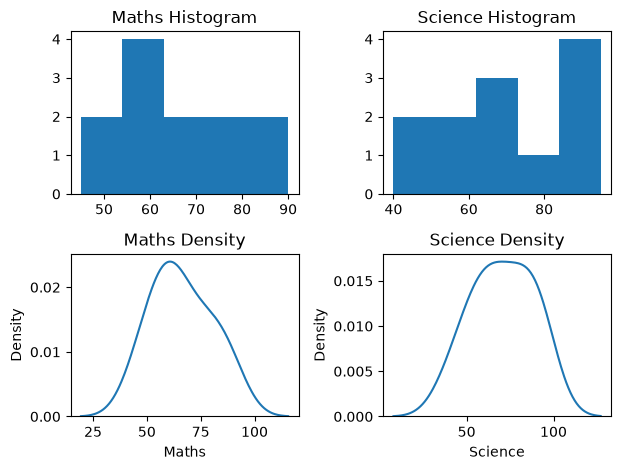

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('marks.csv')

plt.subplot(2, 2, 1)
plt.hist(df['Maths'], bins=5)
plt.title('Maths Histogram')

plt.subplot(2, 2, 2)
plt.hist(df['Science'], bins=5)
plt.title('Science Histogram')

plt.subplot(2, 2, 3)
sns.kdeplot(df['Maths'])
plt.title('Maths Density')

plt.subplot(2, 2, 4)
sns.kdeplot(df['Science'])
plt.title('Science Density')

plt.tight_layout()
plt.show()

Q4. Implement a K-Nearest Neighbors (KNN) classifier on the Iris dataset. Evaluate the model using accuracy and a confusion matrix.

In [13]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print(accuracy_score(y_test, pred))
print(confusion_matrix(y_test, pred))

1.0
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
